# Preparación de datos - Demanda de reservas hoteleras

Variable objetivo: **is_canceled** (1 = reserva cancelada, 0 = no cancelada)

1. Integración de los datos
2. Eliminar variables irrelevantes y redundantes
3. Descripción estadística de los datos
4. Limpieza de datos atípicos-errores
5. Limpieza de datos nulos
6. Análisis de correlaciones para redundancias entre todas las variables
7. Análisis de correlaciones para irrelevancias respecto a la objetivo
8. Guardar los datos preparados

*Nota:* el balanceo y las transformaciones (ingeniería de características) no se realizan aquí, se aplican en el notebook de modelamiento.

In [1]:
#Importamos librerías básicas
import pandas as pd # manipulacion dataframes
import numpy as np  # matrices y vectores
import matplotlib.pyplot as plt #gráfica
import seaborn as sns #mapas de calor

import warnings
warnings.simplefilter("ignore")

# 1. Integración de Datos

Los datos vienen de una sola fuente (hotel_bookings.csv), que ya integra las reservas de dos hoteles de Portugal: un hotel resort (H1) y un hotel de ciudad (H2). No se requiere unir otras fuentes.

In [2]:
#Cargamos los datos
data = pd.read_csv("hotel_bookings.csv")
data.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
#Conocemos los datos
print(data.shape)
data.info()

(119390, 32)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  mea

In [4]:
#Corrección de tipos de datos: variables que son categorías
categorias = ['hotel', 'is_canceled', 'arrival_date_month', 'meal', 'country', 'market_segment',
              'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'assigned_room_type',
              'deposit_type', 'customer_type', 'reservation_status']

data[categorias] = data[categorias].astype('category')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype   
---  ------                          --------------   -----   
 0   hotel                           119390 non-null  category
 1   is_canceled                     119390 non-null  category
 2   lead_time                       119390 non-null  int64   
 3   arrival_date_year               119390 non-null  int64   
 4   arrival_date_month              119390 non-null  category
 5   arrival_date_week_number        119390 non-null  int64   
 6   arrival_date_day_of_month       119390 non-null  int64   
 7   stays_in_weekend_nights         119390 non-null  int64   
 8   stays_in_week_nights            119390 non-null  int64   
 9   adults                          119390 non-null  int64   
 10  children                        119386 non-null  float64 
 11  babies                          119390 non-null  int64   
 12  me

# 2. Eliminar variables irrelevantes y redundantes
* Irrelevantes: ids y códigos. También variables que se conocen después de la cancelación (fuga de información).
* Redundantes: validación por fórmula matemática o variables que repiten la información.

In [5]:
#reservation_status repite la variable objetivo: Canceled y No-Show = cancelada (1)
pd.crosstab(data['reservation_status'], data['is_canceled'])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


In [6]:
#Variables a eliminar
irrelevantes = ['agent', 'company',                 #códigos de agencia y empresa
                'reservation_status_date',          #fecha del último estado (se conoce después de cancelar)
                'assigned_room_type']               #habitación asignada al llegar (se conoce después)
redundantes = ['reservation_status',                #misma información que is_canceled
               'arrival_date_week_number']          #se calcula con año, mes y día de llegada

data = data.drop(columns=irrelevantes + redundantes)
data.shape

(119390, 26)

# 3. Descripción estadística

In [7]:
#Configuración de variables
objetivo = 'is_canceled'
numericas = list(data.select_dtypes('number').columns)
categoricas = [c for c in data.select_dtypes('category').columns if c != objetivo]
print("Numéricas:", numericas)
print("Categóricas:", categoricas)

Numéricas: ['lead_time', 'arrival_date_year', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categóricas: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'deposit_type', 'customer_type']


**Variables numéricas**

In [8]:
#Descripción de variables numéricas
data.describe().T

,count,mean,std,min,25%,50%,75%,max
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0
previous_cancellations,119390.0,0.087118,0.844336,0.00,0.00,0.000,0.0,26.0
previous_bookings_not_canceled,119390.0,0.137097,1.497437,0.00,0.00,0.000,0.0,72.0


In [9]:
#Asimetría: valores lejanos a 0 indican distribución asimétrica
data[numericas].skew().round(2)

lead_time                          1.35
arrival_date_year                 -0.23
arrival_date_day_of_month         -0.00
stays_in_weekend_nights            1.38
stays_in_week_nights               2.86
adults                            18.32
children                           4.11
babies                            24.65
previous_cancellations            24.46
previous_bookings_not_canceled    23.54
booking_changes                    6.00
days_in_waiting_list              11.94
adr                               10.53
required_car_parking_spaces        4.16
total_of_special_requests          1.35
dtype: float64

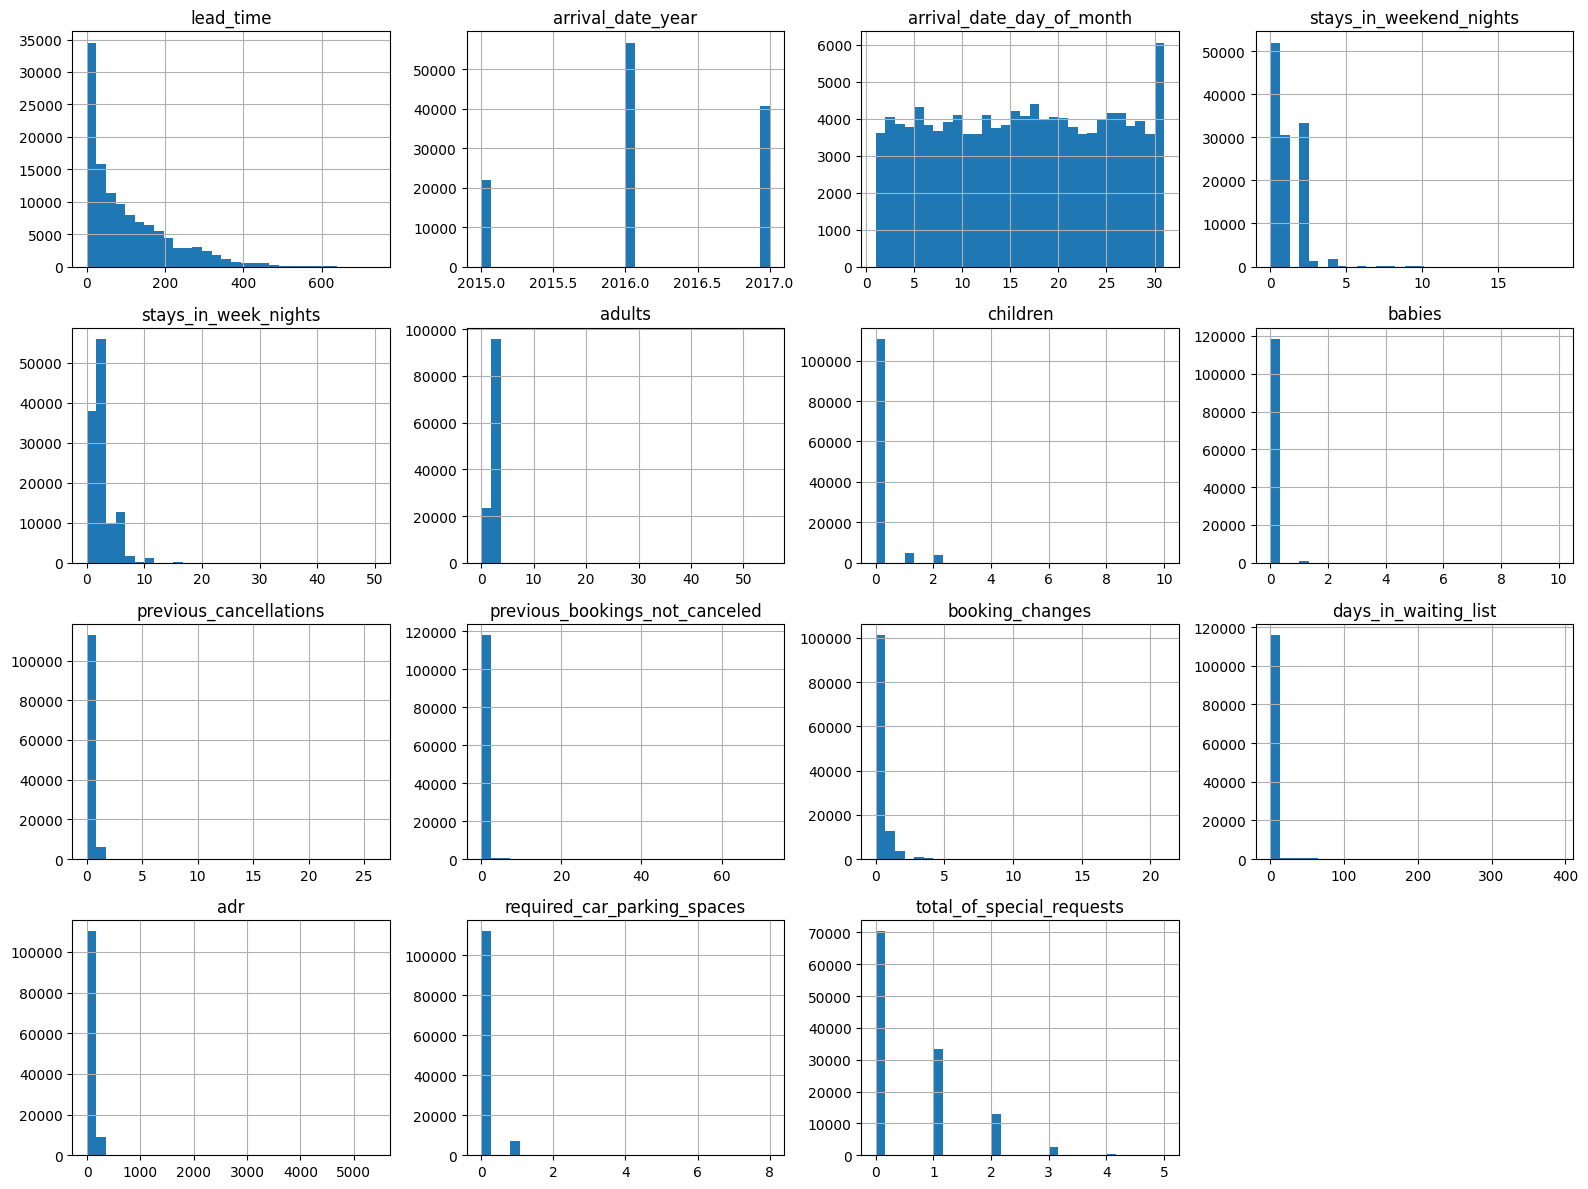

In [10]:
#Histogramas
data[numericas].hist(figsize=(16, 12), bins=30)
plt.tight_layout()

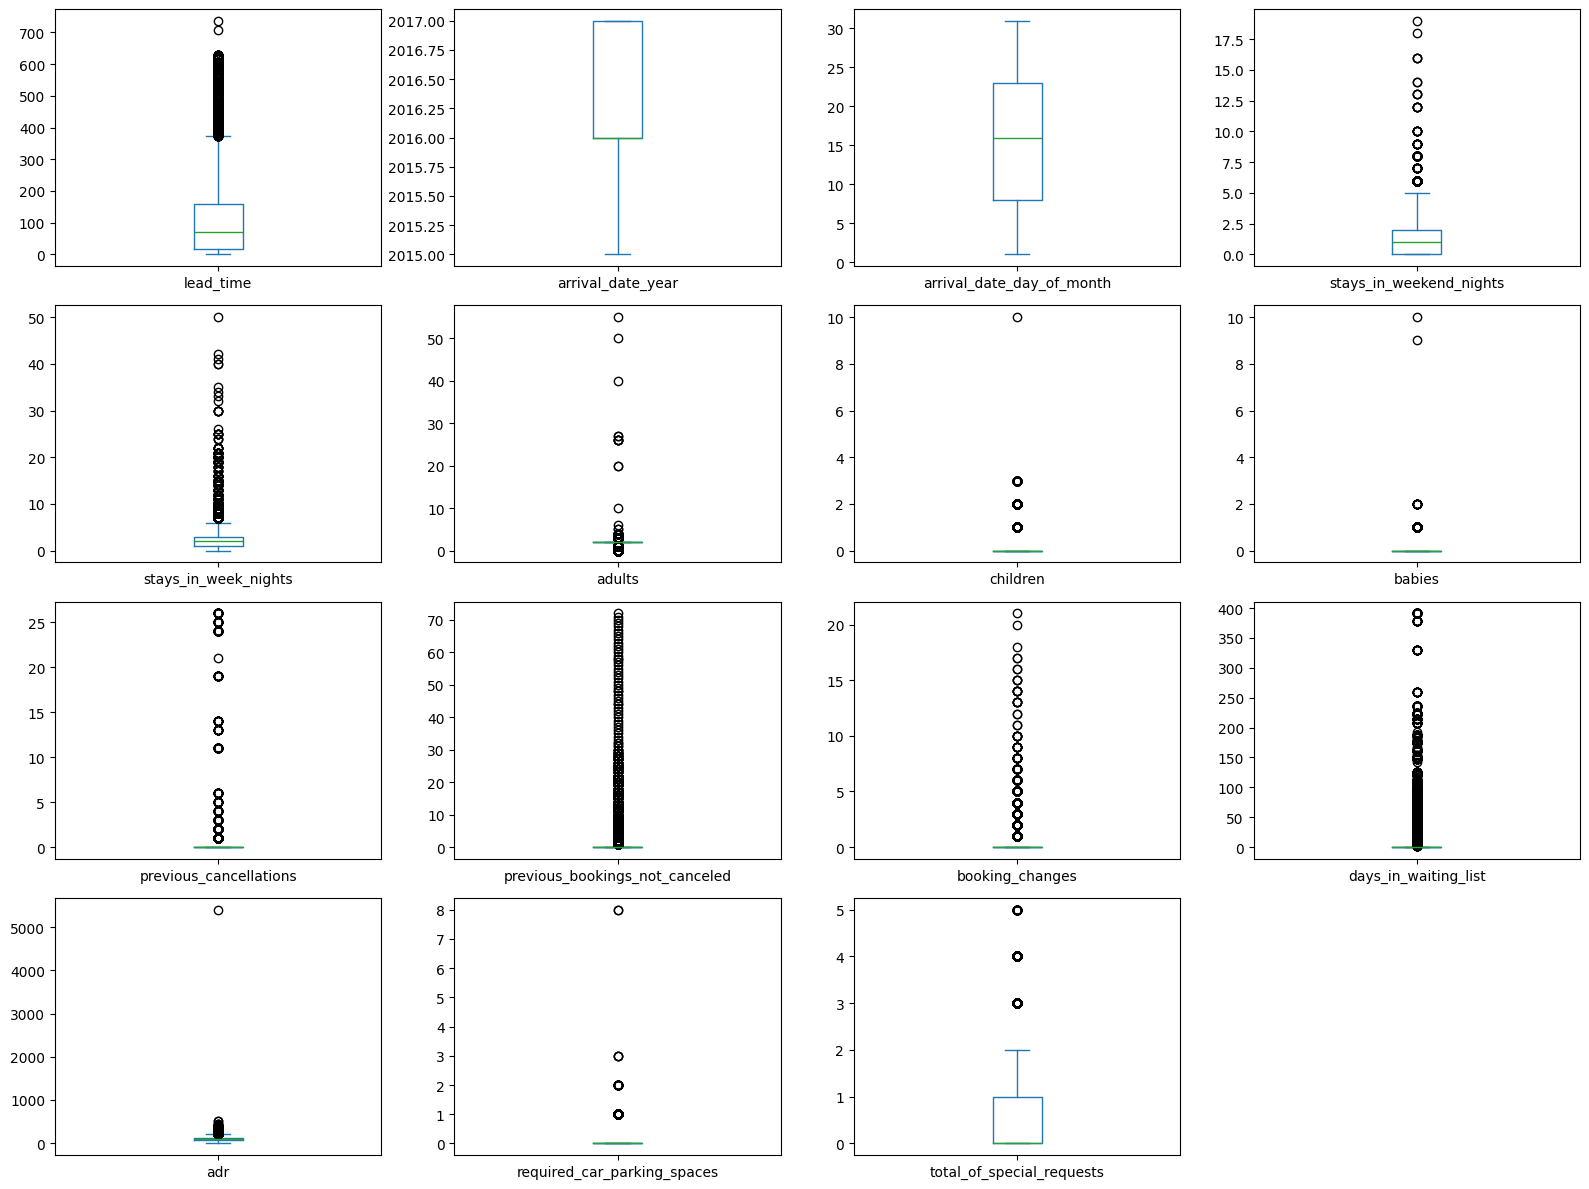

In [11]:
#Diagramas de caja para ver valores extremos
data[numericas].plot(kind='box', subplots=True, layout=(4, 4), figsize=(16, 12))
plt.tight_layout()

**Variables categóricas** (value_counts())

In [12]:
#Descripción de variables categóricas
data[categoricas + [objetivo]].describe().T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
is_repeated_guest,119390,2,0,115580
reserved_room_type,119390,10,A,85994
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


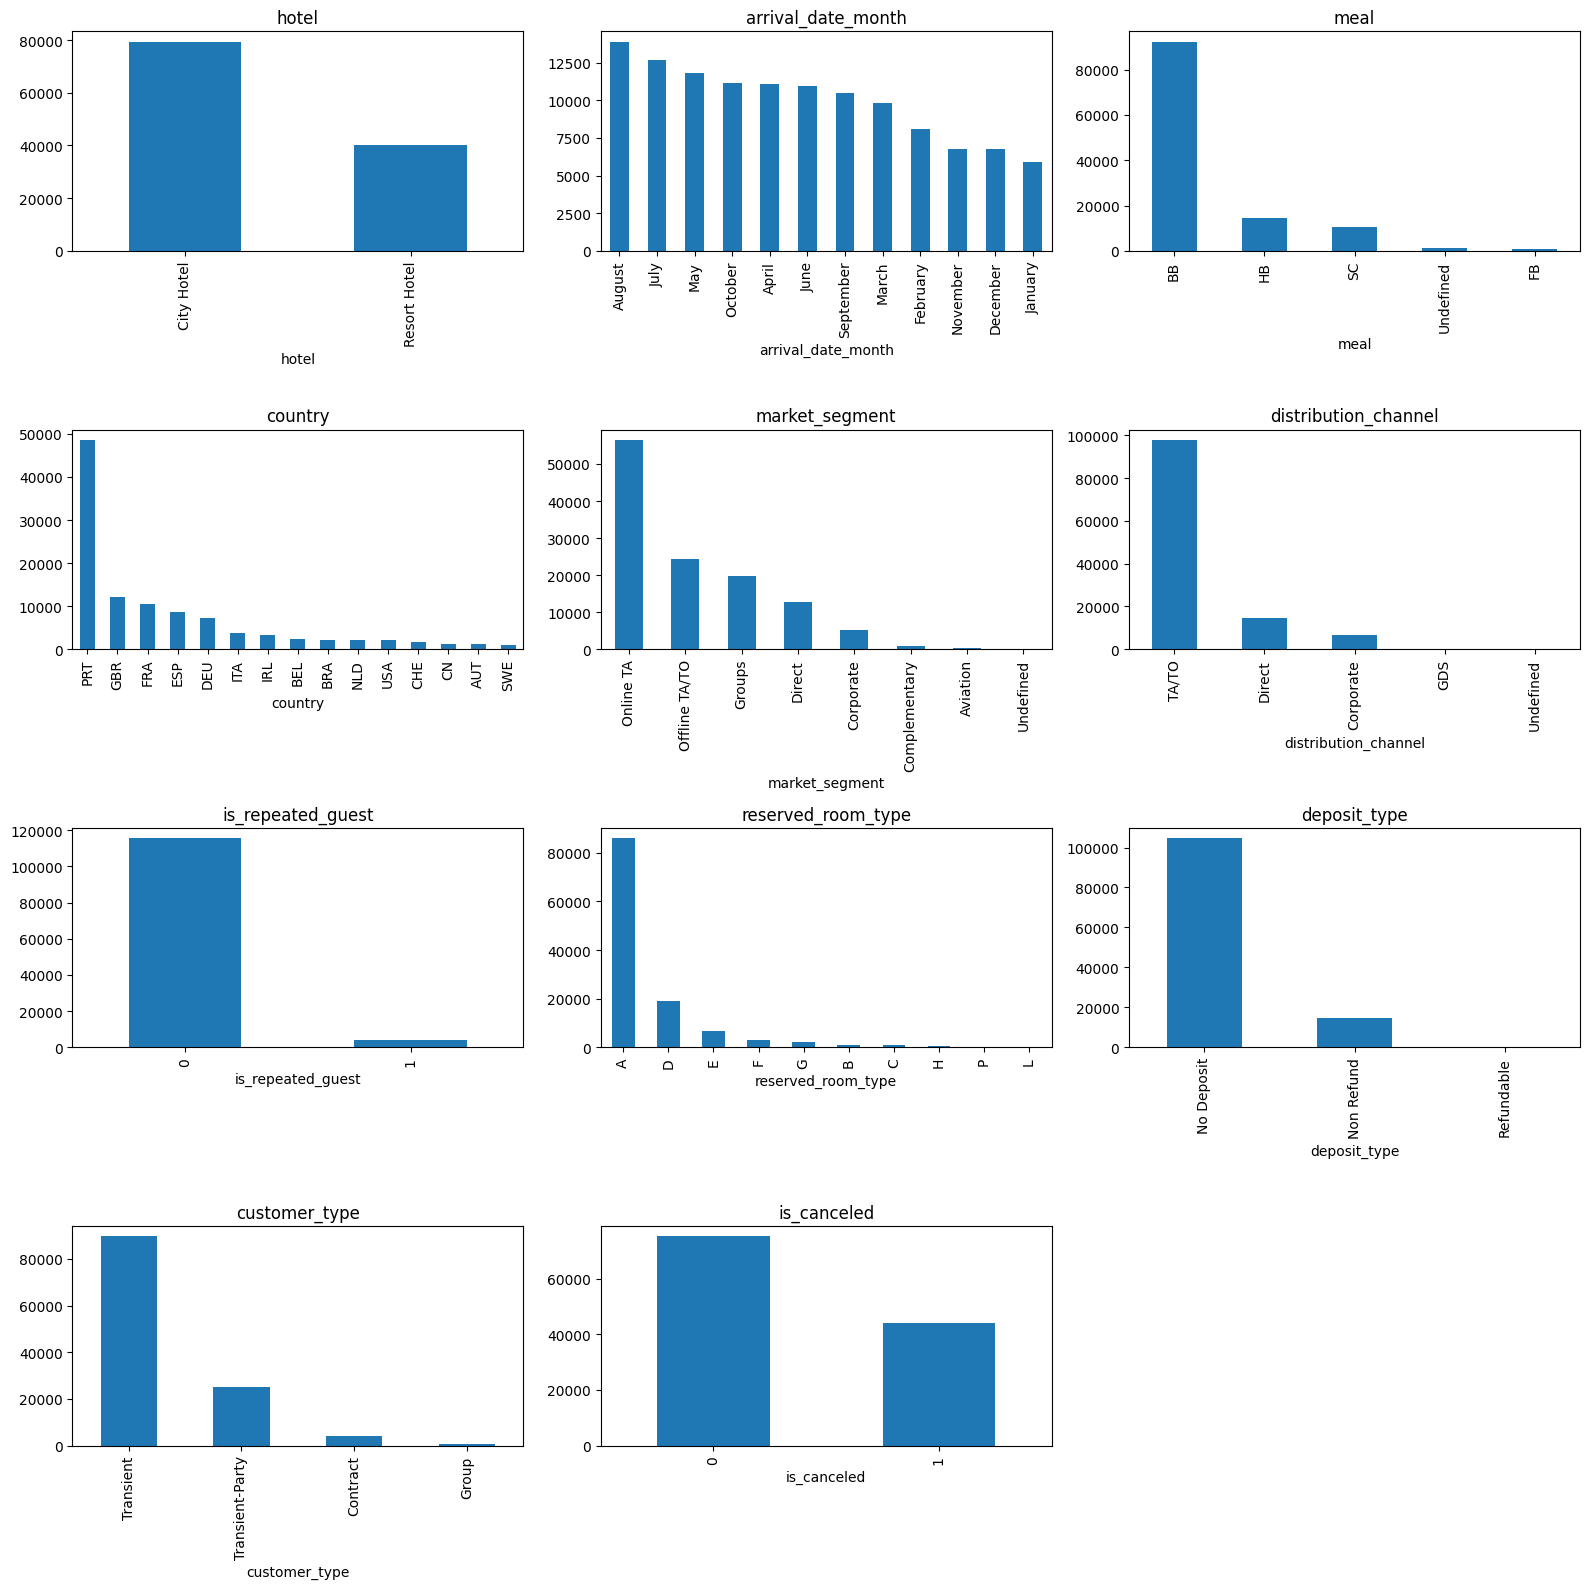

In [13]:
#Gráfica de barras de cada variable categórica (country: solo los 15 países más frecuentes)
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, col in zip(axes.flat, categoricas + [objetivo]):
    data[col].value_counts().head(15).plot(kind='bar', ax=ax, title=col)
for ax in axes.flat[len(categoricas) + 1:]:
    ax.set_visible(False) #se ocultan los espacios vacíos
plt.tight_layout()

In [14]:
#Variable objetivo: proporción de cancelaciones
data[objetivo].value_counts(normalize=True).round(3)

is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64

**Gráficas de las relaciones entre variables**

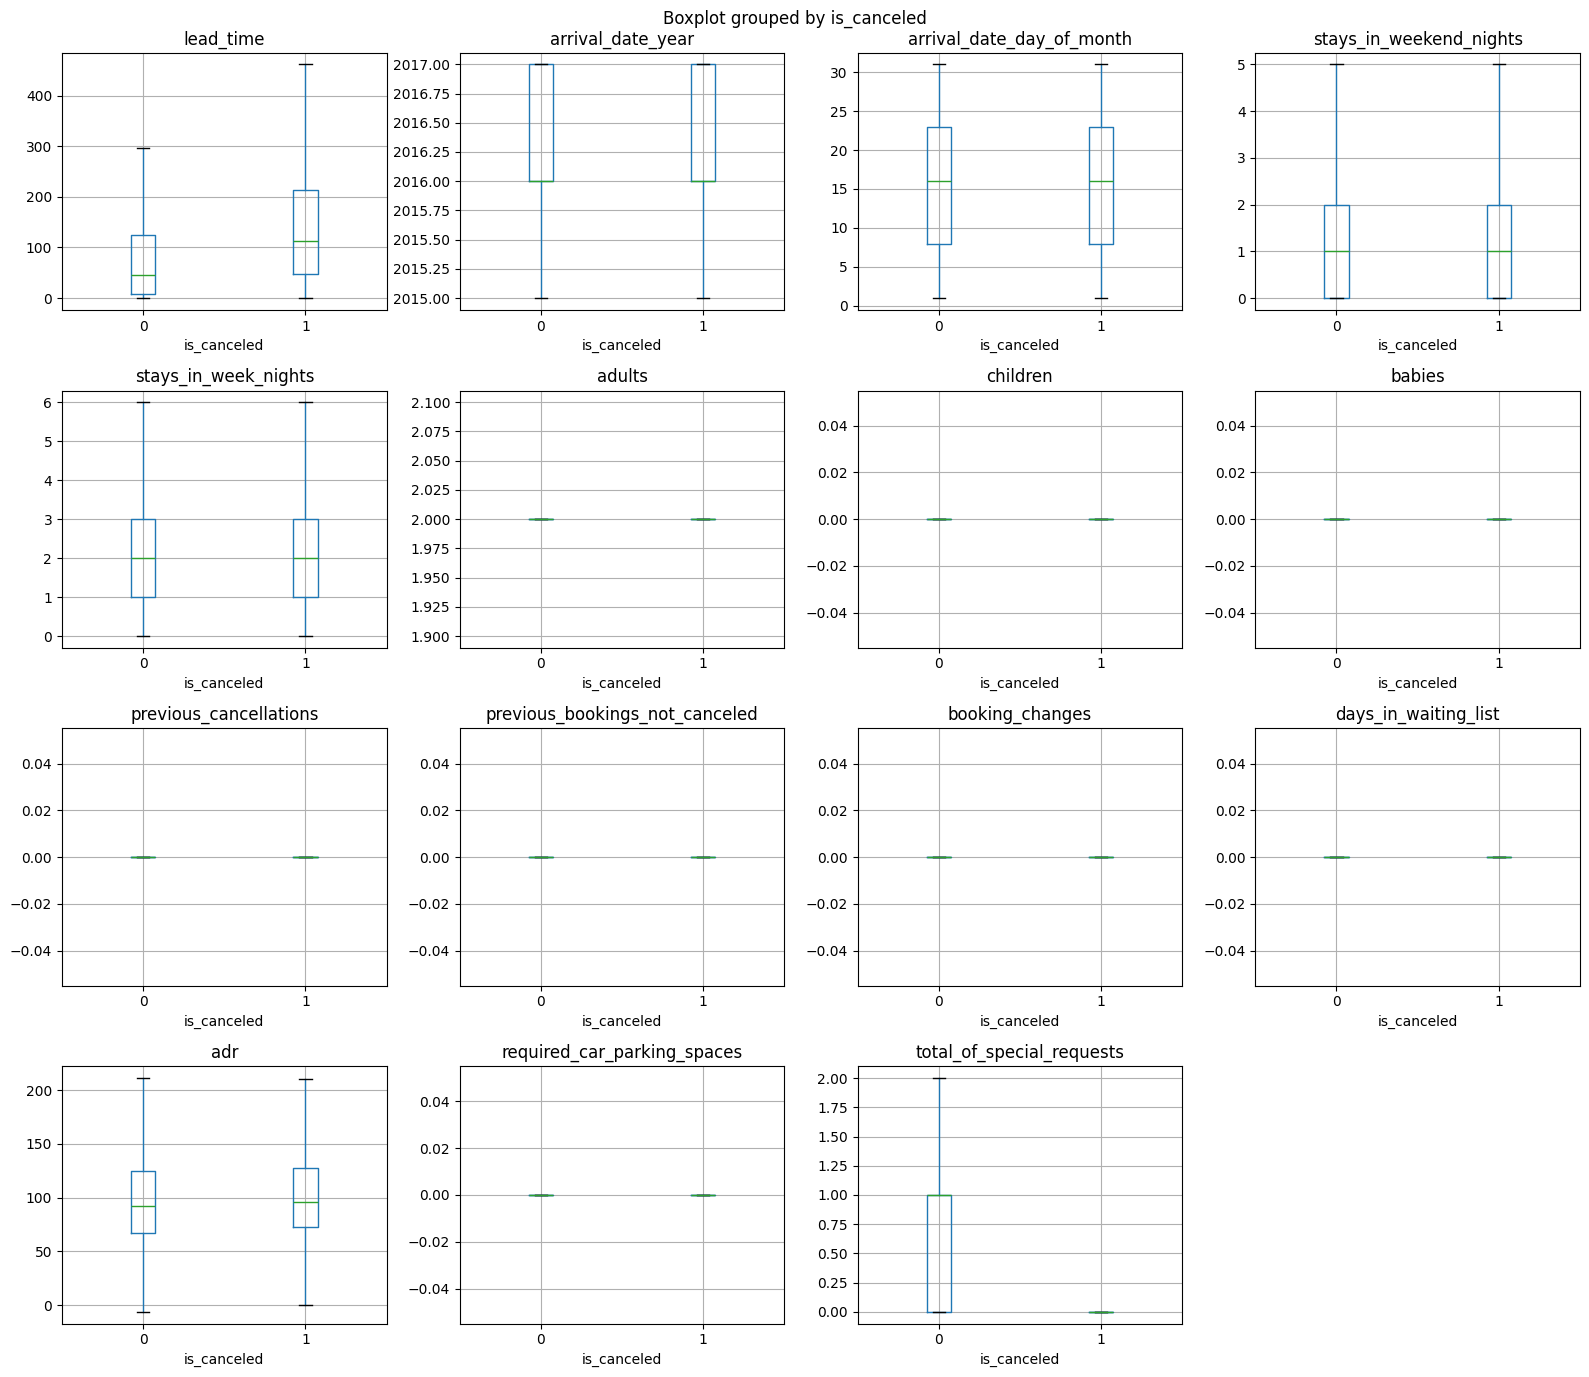

In [15]:
#Variables numéricas vs objetivo
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, col in zip(axes.flat, numericas):
    data.boxplot(column=col, by=objetivo, ax=ax, showfliers=False)
for ax in axes.flat[len(numericas):]:
    ax.set_visible(False) #se ocultan los espacios vacíos
plt.tight_layout()

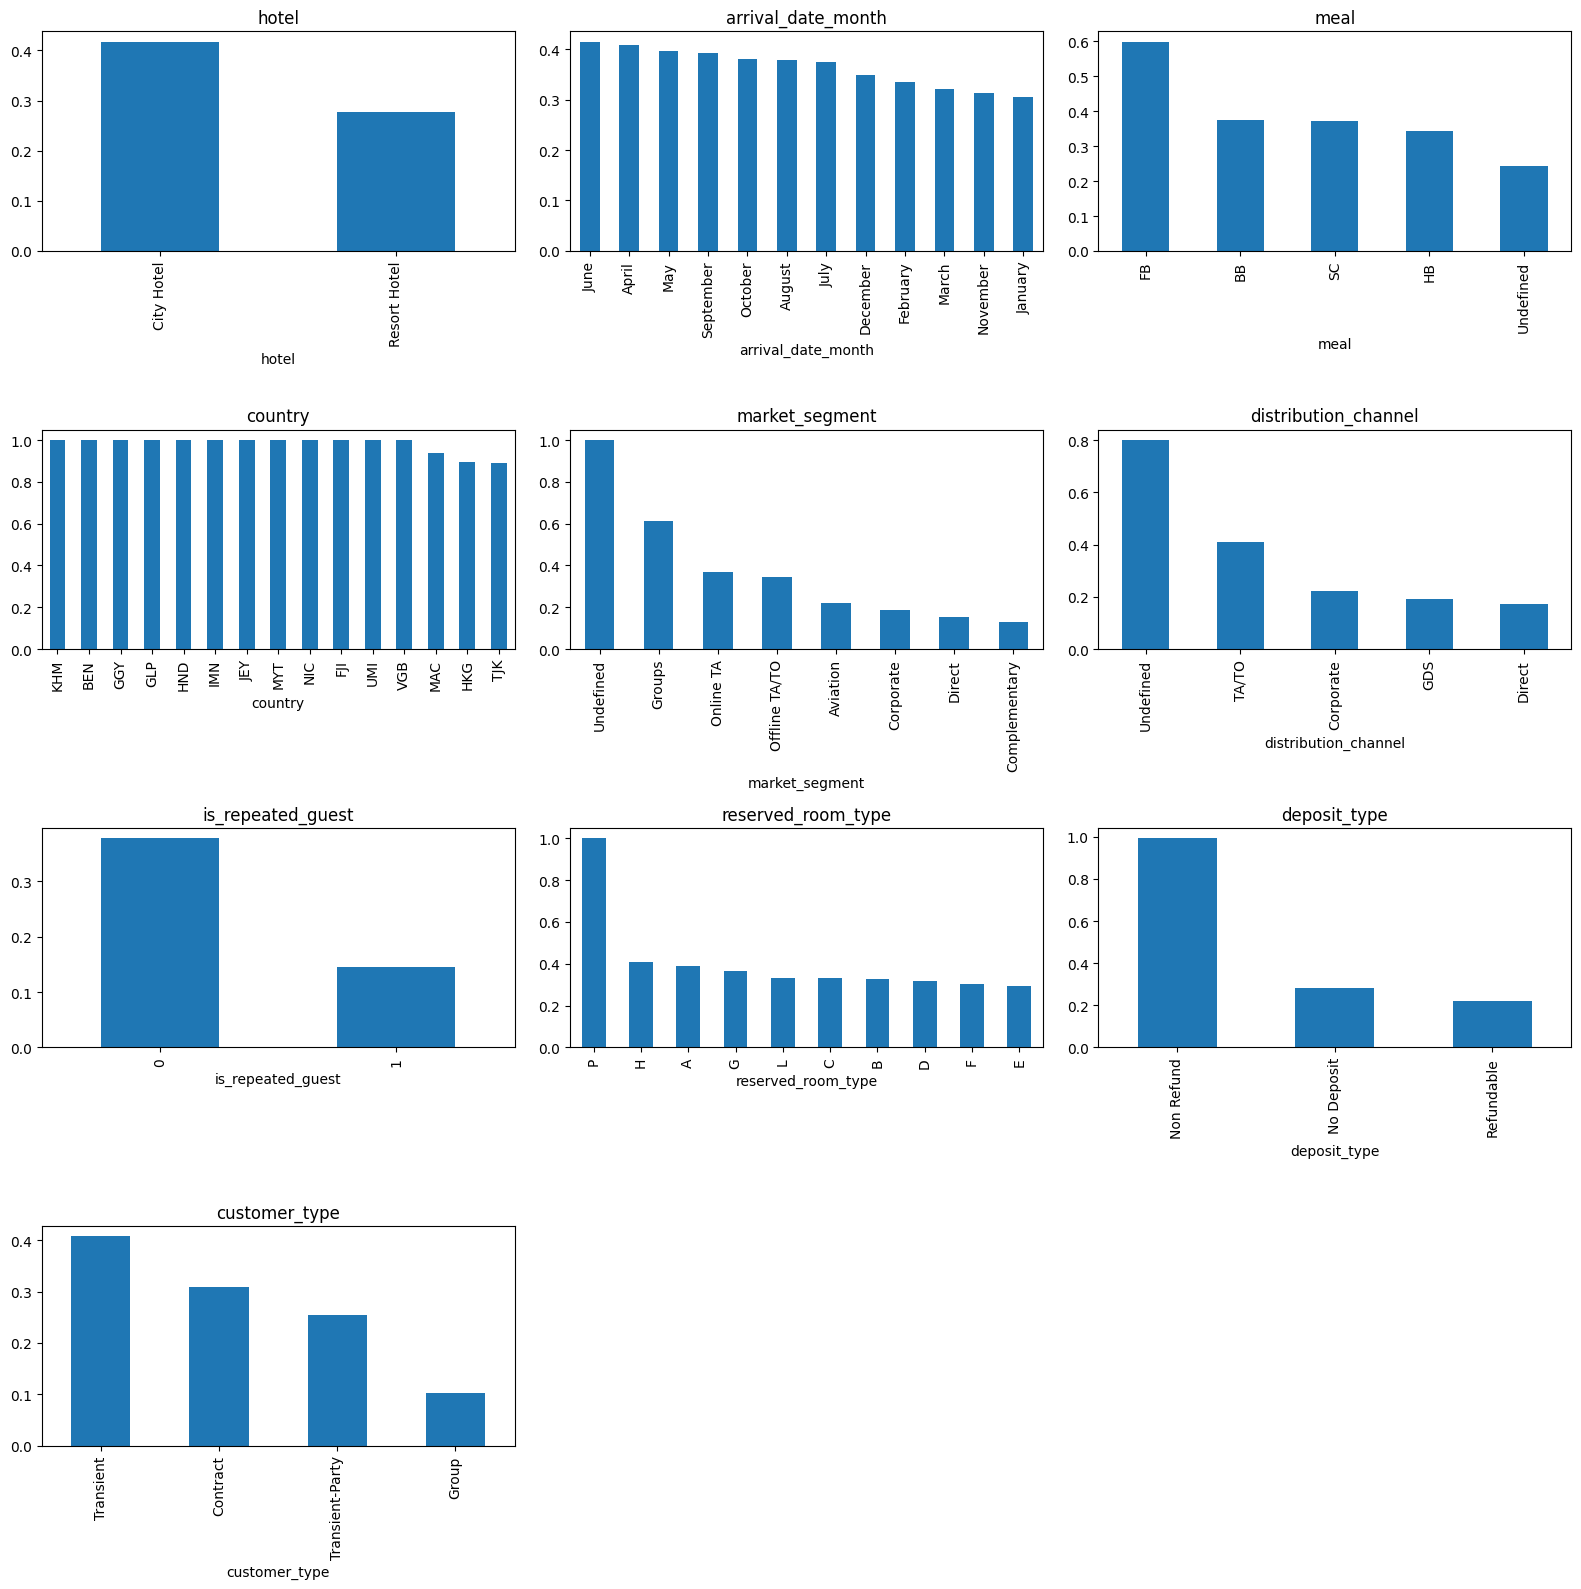

In [16]:
#Variables categóricas vs objetivo: tasa de cancelación por categoría
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, col in zip(axes.flat, categoricas):
    tasa = data.groupby(col)[objetivo].apply(lambda x: (x == 1).mean())
    tasa.sort_values(ascending=False).head(15).plot(kind='bar', ax=ax, title=col)
for ax in axes.flat[len(categoricas):]:
    ax.set_visible(False) #se ocultan los espacios vacíos
plt.tight_layout()

**Perfilado de datos**

Se genera el reporte de ydata-profiling (pandas profiling) y se guarda en un archivo html.

In [17]:
#Ydata-profiling
from ydata_profiling import ProfileReport

perfil = ProfileReport(data, title="Perfilado - Reservas hoteleras", progress_bar=False)
perfil.to_file("perfilado_hotel_bookings.html")

  0%|          | 0/26 [00:00<?, ?it/s]

  4%|▍         | 1/26 [00:00<00:12,  2.04it/s]

100%|██████████| 26/26 [00:00<00:00, 47.15it/s]

# 4. Limpieza de datos atípicos-errores
- Sólo se limpian errores: valores que no cumplen las reglas de calidad del negocio.
- Los valores con error se convierten en nulos y se imputan en el paso 5.
- Los registros sin ningún huésped son inconsistentes y se eliminan.

In [18]:
#Reglas de calidad: rango permitido para variables numéricas
reglas_num = {'adults': (0, 10),
              'children': (0, 5),
              'babies': (0, 5),
              'required_car_parking_spaces': (0, 5),
              'adr': (0, 1000)}

#Reglas de calidad: categorías permitidas
reglas_cat = {'meal': ['BB', 'HB', 'FB', 'SC'],
              'market_segment': ['Online TA', 'Offline TA/TO', 'Groups', 'Direct', 'Corporate', 'Complementary', 'Aviation'],
              'distribution_channel': ['TA/TO', 'Direct', 'Corporate', 'GDS']}

In [19]:
#Función que compara los datos con las reglas de calidad
def revisar_reglas(data):
    filas = []
    for col, (minimo, maximo) in reglas_num.items():
        errores = ((data[col] < minimo) | (data[col] > maximo)).sum()
        filas.append([col, f"{minimo}-{maximo}", f"{data[col].min()}-{data[col].max()}", errores])
    for col, permitidas in reglas_cat.items():
        presentes = list(data[col].dropna().unique())
        errores = (~data[col].isin(permitidas) & data[col].notna()).sum()
        filas.append([col, ", ".join(permitidas), ", ".join(map(str, presentes)), errores])
    return pd.DataFrame(filas, columns=['Variable', 'Regla', 'Datos', 'Errores'])

revisar_reglas(data)

,Variable,Regla,Datos,Errores
0,adults,0-10,0-55,12
1,children,0-5,0.0-10.0,1
2,babies,0-5,0-10,2
3,required_car_parking_spaces,0-5,0-8,2
4,adr,0-1000,-6.38-5400.0,2
5,meal,"BB, HB, FB, SC","BB, FB, HB, SC, Undefined",1169
6,market_segment,"Online TA, Offline TA/TO, Groups, Direct, Corp...","Direct, Corporate, Online TA, Offline TA/TO, C...",2
7,distribution_channel,"TA/TO, Direct, Corporate, GDS","Direct, Corporate, TA/TO, Undefined, GDS",5


In [20]:
#Registros sin huéspedes (adultos + niños + bebés = 0)
sin_huespedes = (data['adults'] + data['children'].fillna(0) + data['babies']) == 0
print("Registros sin huéspedes:", sin_huespedes.sum())
data = data[~sin_huespedes]

Registros sin huéspedes: 180


In [21]:
#meal: según el diccionario de datos, Undefined y SC significan lo mismo (sin plan de comidas)
data['meal'] = data['meal'].replace({'Undefined': 'SC'})

In [22]:
#Valores numéricos fuera de rango -> nulo
for col, (minimo, maximo) in reglas_num.items():
    data.loc[(data[col] < minimo) | (data[col] > maximo), col] = np.nan

#Categorías no permitidas (Undefined) -> nulo
for col, permitidas in reglas_cat.items():
    data[col] = data[col].astype('object').where(data[col].isin(permitidas)).astype('category')

revisar_reglas(data)

,Variable,Regla,Datos,Errores
0,adults,0-10,0.0-10.0,0
1,children,0-5,0.0-3.0,0
2,babies,0-5,0.0-2.0,0
3,required_car_parking_spaces,0-5,0.0-3.0,0
4,adr,0-1000,0.0-510.0,0
5,meal,"BB, HB, FB, SC","BB, FB, HB, SC",0
6,market_segment,"Online TA, Offline TA/TO, Groups, Direct, Corp...","Direct, Corporate, Online TA, Offline TA/TO, C...",0
7,distribution_channel,"TA/TO, Direct, Corporate, GDS","Direct, Corporate, TA/TO, GDS",0


In [23]:
#Registros duplicados: no hay id de reserva, filas iguales pueden ser varias habitaciones de un mismo grupo
print("Registros duplicados:", data.duplicated().sum())

Registros duplicados: 33258


Los duplicados no se eliminan: el conjunto no tiene identificador de reserva, y reservas idénticas en la misma fecha corresponden a grupos que reservan varias habitaciones iguales.

# 5. Limpieza de datos nulos: Imputación

Estrategia:
* Eliminar registros con mas de 15% de nulos
* Eliminar columnas con mas de 15% de nulos
* Imputar por media (numérica simétrica), mediana (numérica asimétrica) o moda (categórica). No se puede imputar más allá del 15% de los datos.

In [24]:
#Porcentaje de nulos por variable
nulos = data.isna().mean() * 100
nulos[nulos > 0].round(3)

adults                         0.010
children                       0.004
babies                         0.002
country                        0.401
market_segment                 0.002
distribution_channel           0.004
adr                            0.002
required_car_parking_spaces    0.002
dtype: float64

In [25]:
#Registros con más del 15% de nulos
nulos_fila = data.isna().mean(axis=1) * 100
print("Registros con más del 15% de nulos:", (nulos_fila > 15).sum())
data = data[nulos_fila <= 15]

Registros con más del 15% de nulos: 0


In [26]:
#Variables con más del 15% de nulos
print("Variables con más del 15% de nulos:", list(nulos[nulos > 15].index))

Variables con más del 15% de nulos: []


In [27]:
#Variables de conteo (número de personas o parqueaderos): el valor imputado se redondea
conteos = ['adults', 'children', 'babies', 'required_car_parking_spaces']

#Imputación: media si es simétrica, mediana si es asimétrica, moda si es categórica
for col in data.columns[data.isna().any()]:
    if col in numericas:
        simetrica = abs(data[col].skew()) < 0.5
        valor = data[col].mean() if simetrica else data[col].median()
        metodo = 'media' if simetrica else 'mediana'
        if col in conteos:
            valor = round(valor)
    else:
        valor = data[col].mode()[0]
        metodo = 'moda'
    print(f"{col}: {data[col].isna().sum()} nulos imputados por la {metodo} = {valor}")
    data[col] = data[col].fillna(valor)

adults: 12 nulos imputados por la media = 2
children: 5 nulos imputados por la mediana = 0
babies: 2 nulos imputados por la mediana = 0
country: 478 nulos imputados por la moda = PRT
market_segment: 2 nulos imputados por la moda = Online TA
distribution_channel: 5 nulos imputados por la moda = TA/TO
adr: 2 nulos imputados por la mediana = 94.95
required_car_parking_spaces: 2 nulos imputados por la mediana = 0


In [28]:
#Verificación
data.isna().sum().sum()

0

In [29]:
#Las variables de conteo ya no tienen nulos, se pasan a entero
data[conteos] = data[conteos].astype(int)
data.describe().T

,count,mean,std,min,25%,50%,75%,max
lead_time,119210.0,104.109227,106.875450,0.0,18.0,69.00,161.0,737.0
arrival_date_year,119210.0,2016.156472,0.707485,2015.0,2016.0,2016.00,2017.0,2017.0
arrival_date_day_of_month,119210.0,15.798717,8.781070,1.0,8.0,16.00,23.0,31.0
stays_in_weekend_nights,119210.0,0.927053,0.995117,0.0,0.0,1.00,2.0,19.0
stays_in_week_nights,119210.0,2.499195,1.897106,0.0,1.0,2.00,3.0,50.0
adults,119210.0,1.856312,0.484696,0.0,2.0,2.00,2.0,10.0
children,119210.0,0.103959,0.397804,0.0,0.0,0.00,0.0,3.0
babies,119210.0,0.007801,0.089399,0.0,0.0,0.00,0.0,2.0
previous_cancellations,119210.0,0.087191,0.844918,0.0,0.0,0.00,0.0,26.0
previous_bookings_not_canceled,119210.0,0.137094,1.498137,0.0,0.0,0.00,0.0,72.0


# 6. Correlaciones para redundancias

* Numéricas: correlación de Pearson
* Categóricas: V de Cramer (asociación entre categorías, va de 0 a 1)

**Correlaciones para redundancia= mayores |0.8|**

<Axes: >

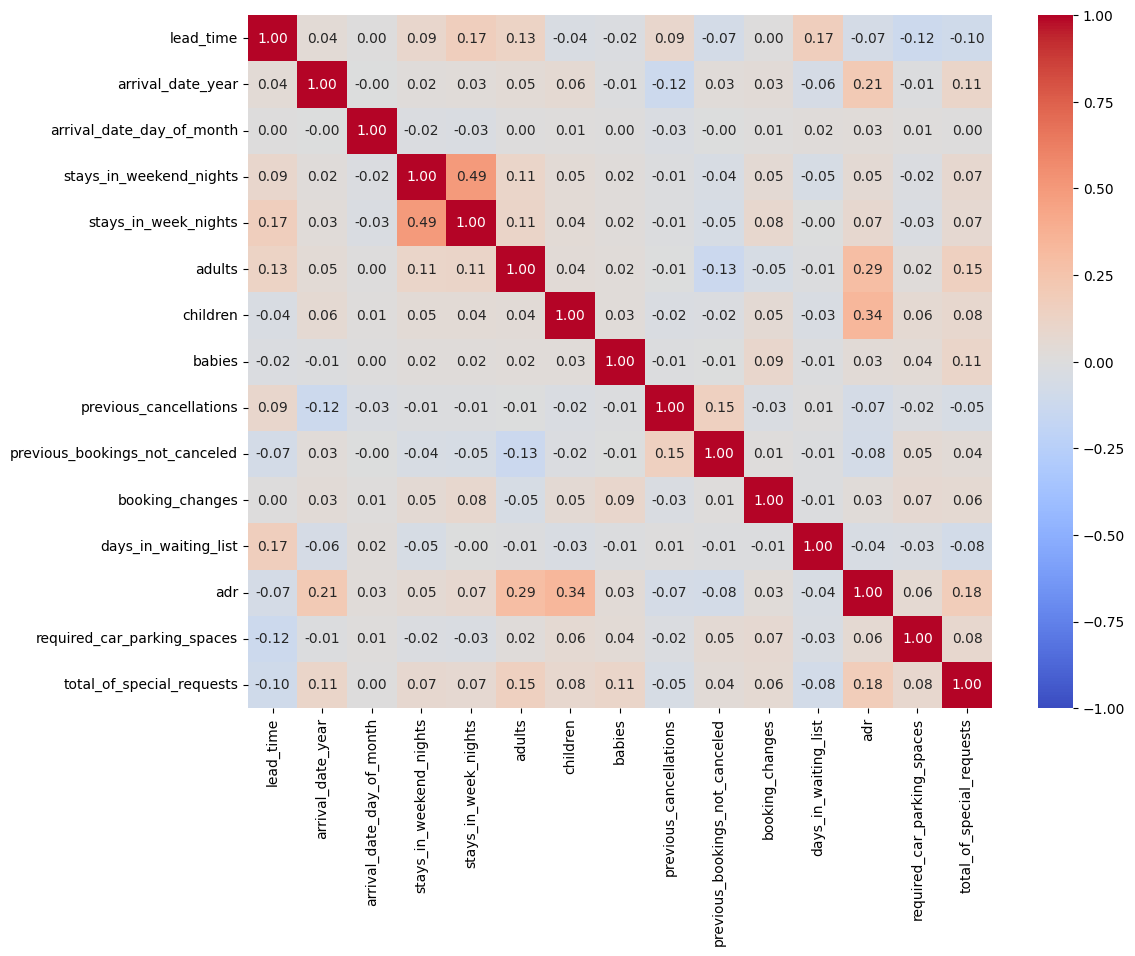

In [30]:
#Correlación entre variables numéricas
corr = data[numericas].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)

In [31]:
#Función que lista los pares de variables con correlación mayor a |0.8|
def pares_redundantes(matriz, umbral=0.8):
    pares = matriz.where(np.triu(np.ones(matriz.shape, dtype=bool), k=1)).stack()
    return pares[pares.abs() > umbral]

pares_redundantes(corr)

Series([], dtype: float64)

In [32]:
#V de Cramer entre dos variables categóricas
from scipy.stats import chi2_contingency

def cramer_v(x, y):
    tabla = pd.crosstab(x.astype(str), y.astype(str))
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.values.sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

<Axes: >

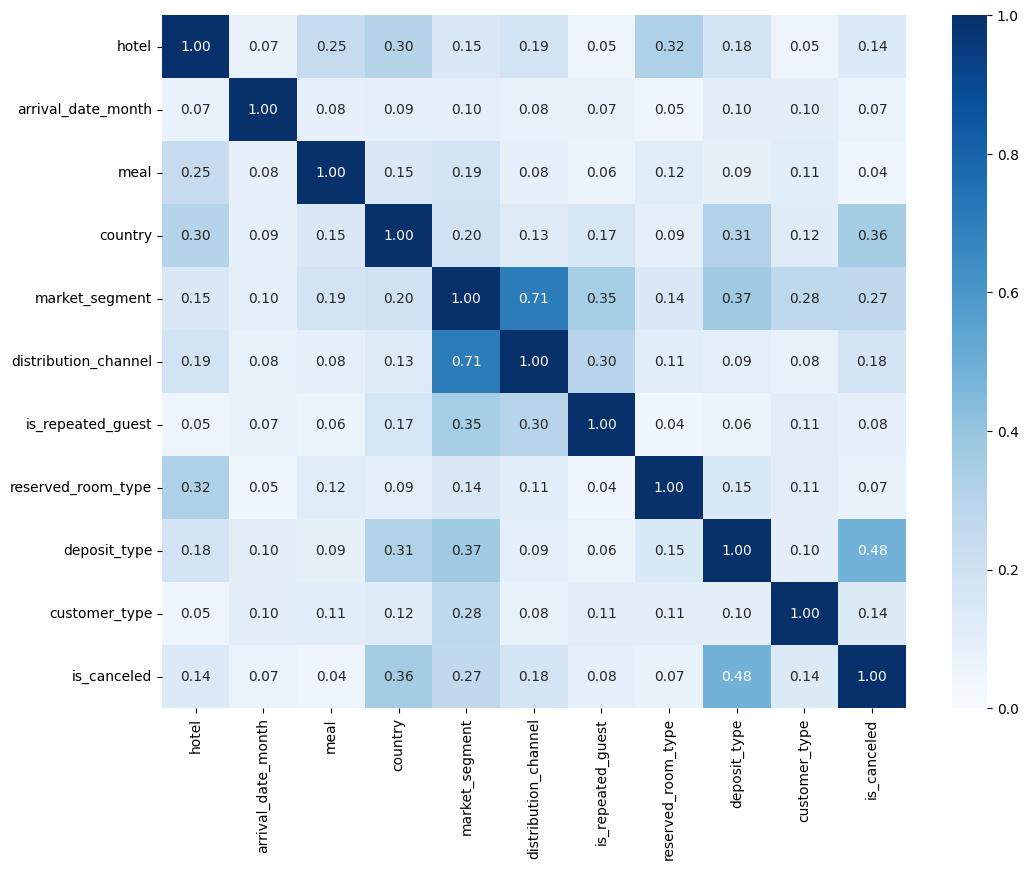

In [33]:
#Asociación entre variables categóricas (incluye la objetivo)
variables_cat = categoricas + [objetivo]
cramer = pd.DataFrame(index=variables_cat, columns=variables_cat, dtype=float)
for a in variables_cat:
    for b in variables_cat:
        cramer.loc[a, b] = cramer_v(data[a], data[b])

plt.figure(figsize=(12, 9))
sns.heatmap(cramer, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)

In [34]:
pares_redundantes(cramer)

Series([], dtype: float64)

# 7. Correlaciones para irrelevancia con la variable objetivo

Se buscan correlaciones con la variable objetivo muy bajas (0.0-0.05)

total_of_special_requests        -0.2349
required_car_parking_spaces      -0.1970
booking_changes                  -0.1448
previous_bookings_not_canceled   -0.0574
babies                           -0.0342
arrival_date_day_of_month        -0.0059
stays_in_weekend_nights          -0.0013
children                          0.0046
arrival_date_year                 0.0166
stays_in_week_nights              0.0255
adr                               0.0476
days_in_waiting_list              0.0543
adults                            0.0613
previous_cancellations            0.1101
lead_time                         0.2929
dtype: float64

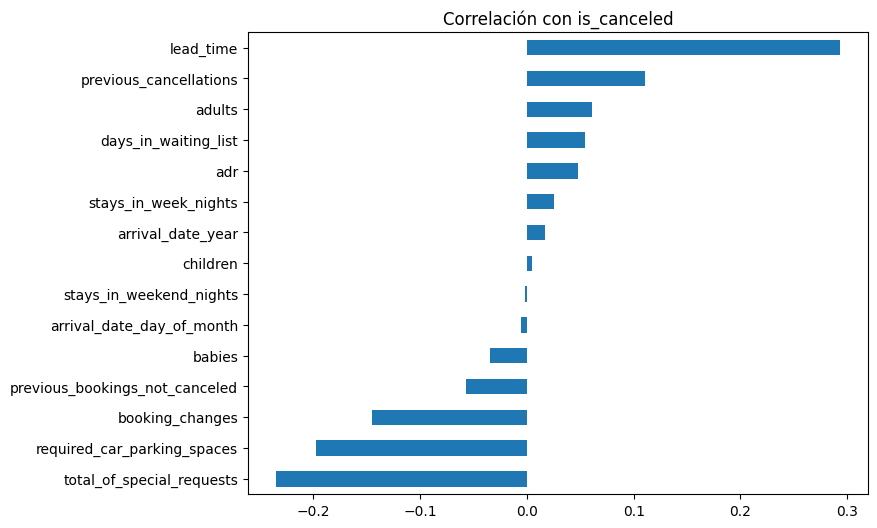

In [35]:
#Numéricas vs objetivo (Pearson)
corr_objetivo = data[numericas].corrwith(data[objetivo].astype(int))
corr_objetivo.sort_values().plot(kind='barh', figsize=(8, 6), title='Correlación con is_canceled')
corr_objetivo.round(4).sort_values()

In [36]:
#Categóricas vs objetivo (V de Cramer) -> ultima fila
cramer.loc[objetivo, categoricas].round(4).sort_values()

meal                    0.0439
arrival_date_month      0.0699
reserved_room_type      0.0728
is_repeated_guest       0.0837
customer_type           0.1366
hotel                   0.1371
distribution_channel    0.1771
market_segment          0.2670
country                 0.3572
deposit_type            0.4815
Name: is_canceled, dtype: float64

In [37]:
#Variables irrelevantes: correlación con la objetivo menor a 0.05
asociacion = pd.concat([corr_objetivo.abs(), cramer.loc[objetivo, categoricas]])
irrelevantes_obj = list(asociacion[asociacion < 0.05].index)
print("Variables irrelevantes:", irrelevantes_obj)

data = data.drop(columns=irrelevantes_obj)
data.info()

Variables irrelevantes: ['arrival_date_year', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'children', 'babies', 'adr', 'meal']
<class 'pandas.core.frame.DataFrame'>
Index: 119210 entries, 0 to 119389
Data columns (total 18 columns):
 #   Column                          Non-Null Count   Dtype   
---  ------                          --------------   -----   
 0   hotel                           119210 non-null  category
 1   is_canceled                     119210 non-null  category
 2   lead_time                       119210 non-null  int64   
 3   arrival_date_month              119210 non-null  category
 4   adults                          119210 non-null  int32   
 5   country                         119210 non-null  category
 6   market_segment                  119210 non-null  category
 7   distribution_channel            119210 non-null  category
 8   is_repeated_guest               119210 non-null  category
 9   previous_cancellations          1

# 8. Guardar los datos preparados

In [38]:
#Se guardan los datos sin balanceo ni transformaciones
data.to_csv("hotel_bookings_preparado.csv", index=False)
data.shape

(119210, 18)

# **FIN**